# 33 - Round 2: pre-registered validation at ~163M (the GPU's ceiling)

Round 1 (91M) showed polynomials overshoot because effects saturate. This round tests the fix
prospectively: the bounded **saturating family** vs linear, forecasting ~163M (960d/14L/12h - the
largest size that fits in 8 GB) for all three interventions, **committed before any 163M model
exists**. Cell order: smoke test -> pre-registration -> 8 training runs -> grading.

Key questions this round answers: does conv's plateau (~-10%) hold at 163M? does diff *ever* win
under this budget? does the saturating family earn its place prospectively (not just by
retrodiction)? and does the held-out MTP forecast survive a further quarter-decade?


In [1]:
%matplotlib inline
import os, math, time, csv, json, gc
from contextlib import nullcontext
import numpy as np
import torch
from model import Config, GPT, count_params

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
D = "../dataset"
train_data = torch.from_numpy(np.load(D + "/wt103_bpe_train.npy"))
val_data = torch.from_numpy(np.load(D + "/wt103_bpe_val.npy"))
vocab = json.load(open(D + "/wt103_bpe_meta.json"))["vocab"]
print(f"vocab={vocab}  train={len(train_data):,}  val={len(val_data):,}")

BLOCK, BATCH = 256, 16
CKPT_DIR = "../results/val160_ckpt"
os.makedirs(CKPT_DIR, exist_ok=True)

COMBO = {"pos_encoding": "rope", "activation": "swiglu", "norm_placement": "pre", "norm_type": "rmsnorm",
         "grad_ckpt": True}   # activation checkpointing: identical protocol, fits 163M in 8GB
VARIANTS = {"combo": COMBO, "combo_conv3": {**COMBO, "conv_kernel": 3},
            "combo_diff": {**COMBO, "attention": "diff"}, "combo_mtp": {**COMBO, "mtp_weight": 0.5}}
SIZE160 = (960, 14, 12)   # ~163.8M params, head_dim 80; 8.11GB WITHOUT ckpt (smoke-tested) -> needs grad_ckpt
RUNS_CSV = "../results/val160_runs.csv"
if not os.path.exists(RUNS_CSV):
    with open(RUNS_CSV, "w", newline="") as f:
        csv.writer(f).writerow(["variant", "seed", "params_M", "val_ppl"])

def get_batch(split, gen):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - BLOCK, (BATCH,), generator=gen)
    x = torch.stack([d[i:i + BLOCK] for i in ix]); y = torch.stack([d[i + 1:i + 1 + BLOCK] for i in ix])
    return x.to(device), y.to(device)
def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16) if device == "cuda" else nullcontext()

def train_one(name, size_cfg, over, seed=0, max_iters=6000, eval_iters=200,
              lr=3e-4, warmup=200, min_lr=3e-5, ckpt_every=500):
    ne, nl, nh = size_cfg
    ckpt_path = f"{CKPT_DIR}/{name}_s{seed}.pt"
    torch.manual_seed(seed)
    cfg = Config(vocab_size=vocab, block_size=BLOCK, n_layer=nl, n_head=nh, n_embd=ne,
                 dropout=0.1, **over)
    model = GPT(cfg).to(device)
    pm = count_params(model) / 1e6
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.99), weight_decay=0.1)
    tg = torch.Generator().manual_seed(7777 + seed)
    start_it = 0
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location="cpu")   # cpu: RNG state must stay a CPU ByteTensor
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        tg.set_state(ck["tg"].cpu()); start_it = ck["iter"]
        print(f"    [{name} s{seed}] RESUMED from {start_it}", flush=True)
    def get_lr(it):
        if it < warmup: return lr * (it + 1) / warmup
        r = (it - warmup) / max(1, max_iters - warmup)
        return min_lr + 0.5 * (lr - min_lr) * (1 + math.cos(math.pi * r))
    def save_ckpt(it):
        tmp = ckpt_path + ".tmp"
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "iter": it, "tg": tg.get_state()}, tmp)
        os.replace(tmp, ckpt_path)
    @torch.no_grad()
    def ev():
        model.eval(); g = torch.Generator().manual_seed(4242); tot = 0.0
        for _ in range(eval_iters):
            x, y = get_batch("val", g)
            with autocast_ctx():
                _, loss = model(x, y)
            tot += loss.item()
        model.train(); return tot / eval_iters
    t0 = time.time()
    for it in range(start_it, max_iters):
        for grp in opt.param_groups: grp["lr"] = get_lr(it)
        x, y = get_batch("train", tg)
        with autocast_ctx():
            _, loss = model(x, y)
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if it % 1500 == 0:
            print(f"    [{name} s{seed}] it {it}/{max_iters} loss {loss.item():.3f} {(time.time()-t0)/60:.1f}m", flush=True)
        if (it + 1) % ckpt_every == 0: save_ckpt(it + 1)
    ppl = math.exp(ev())
    if os.path.exists(ckpt_path): os.remove(ckpt_path)
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return ppl, pm

def run160(vname, seed):
    done = set()
    with open(RUNS_CSV) as f:
        r = csv.reader(f); next(r, None)
        for row in r:
            if len(row) == 4: done.add((row[0], row[1]))
    if (vname, str(seed)) in done:
        print(f"  160M {vname} s{seed}: done, skip", flush=True); return
    t0 = time.time()
    p, pm = train_one(f"160M_{vname}", SIZE160, VARIANTS[vname], seed=seed)
    with open(RUNS_CSV, "a", newline="") as f:
        csv.writer(f).writerow([vname, seed, f"{pm:.3f}", f"{p:.4f}"])
    print(f"  160M {vname:12s} seed {seed}: ppl {p:.3f} ({pm:.1f}M) | {(time.time()-t0)/60:.1f} min", flush=True)
print("ready")


device: cuda
vocab=8192  train=14,923,628  val=281,169
ready


In [2]:
# === Stage B1: VRAM smoke test (30 iters + a checkpoint save at ~163M) ===
torch.cuda.reset_peak_memory_stats()
cfg = Config(vocab_size=vocab, block_size=BLOCK, n_layer=SIZE160[1], n_head=SIZE160[2],
             n_embd=SIZE160[0], dropout=0.1, **VARIANTS["combo_mtp"])   # mtp = largest activation footprint
model = GPT(cfg).to(device)
print(f"params: {count_params(model)/1e6:.1f}M")
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.99), weight_decay=0.1)
g = torch.Generator().manual_seed(1)
t0 = time.time()
for it in range(30):
    x, y = get_batch("train", g)
    with autocast_ctx():
        _, loss = model(x, y)
    opt.zero_grad(set_to_none=True); loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
sec_per_it = (time.time() - t0) / 30
tmp = CKPT_DIR + "/smoke.pt"
torch.save({"model": model.state_dict(), "opt": opt.state_dict()}, tmp); os.remove(tmp)
peak = torch.cuda.max_memory_allocated() / 1e9
print(f"peak allocated: {peak:.2f} GB   |   {sec_per_it:.3f} s/it -> est {sec_per_it*6000/60:.0f} min per 6000-it run")
del model, opt; gc.collect(); torch.cuda.empty_cache()
assert peak < 7.0, f"VRAM too tight ({peak:.2f} GB allocated) - fall back to batch 8 x 12000 iters"
print("SMOKE TEST PASSED")


<repo>\.venv\Lib\site-packages\torch\nn\modules\module.py:1329: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:28.)
  return t.to(


params: 163.8M


peak allocated: 4.02 GB   |   0.427 s/it -> est 43 min per 6000-it run
SMOKE TEST PASSED


In [3]:
# === Stage B2: PRE-REGISTER 160M forecasts (fit on ALL <=91M data; no 160M model exists) ===
def load_kv(fn, keyfn, valfn):
    out = {}
    with open(fn) as f:
        r = csv.reader(f); next(r, None)
        for row in r: out[keyfn(row)] = valfn(row)
    return out

lad = load_kv("../results/ladder6000_runs.csv", lambda r: (r[0], r[1], r[2]), lambda r: float(r[4]))
pmd = load_kv("../results/ladder6000_runs.csv", lambda r: r[0], lambda r: float(r[3]))
sc0 = load_kv("../results/scale_confirm_runs.csv", lambda r: r[0], lambda r: float(r[2]))
sc1 = load_kv("../results/scale_confirm_s1_runs.csv", lambda r: r[0], lambda r: float(r[2]))
v90 = load_kv("../results/val90_runs.csv", lambda r: (r[0], r[1]), lambda r: float(r[3]))
mtp = load_kv("../results/mtp_ladder_runs.csv", lambda r: (r[0], r[2]), lambda r: float(r[4]))

X = {sz: math.log10(pmd[sz] * 1e6) for sz in ["5M", "10M", "15M", "20M"]}
X["30M"], X["90M"] = math.log10(29.407e6), math.log10(91.3e6)
X160 = math.log10(162.7e6)
ORDER = ["5M", "10M", "15M", "20M", "30M", "90M"]

def combo_ppl(sz, s):
    if sz in ("5M", "10M", "15M", "20M"): return lad[(sz, "combo", s)]
    if sz == "30M": return (sc0 if s == "0" else sc1)["combo"]
    return v90[("combo", s)]
def var_ppl(variant, sz, s):
    if variant == "combo_mtp": return mtp[(sz if sz != "90M" else "90M", s)]
    if sz in ("5M", "10M", "15M", "20M"): return lad[(sz, variant, s)]
    if sz == "30M": return (sc0 if s == "0" else sc1)[variant]
    return v90[(variant, s)]
def delta_points(variant, sizes):
    pts = []
    for sz in sizes:
        for s in ("0", "1"):
            try:
                pts.append((sz, X[sz], 100.0 * (var_ppl(variant, sz, s) - combo_ppl(sz, s)) / combo_ppl(sz, s)))
            except KeyError:
                pass
    return pts
def monotone_suffix(sizes, pts):
    means = [np.mean([y for z, x, y in pts if z == sz]) for sz in sizes]
    start = len(means) - 2
    while start > 0:
        d1 = means[start + 1] - means[start]; d0 = means[start] - means[start - 1]
        if d0 * d1 >= 0: start -= 1
        else: break
    else:
        start = 0
    return sizes[start:], means
def fit_sat(pts):
    xs = np.array([x for _, x, _ in pts]); ys = np.array([y for _, _, y in pts]); x0 = xs.min()
    best = None
    for k in np.geomspace(0.05, 50, 500):
        e = np.exp(-k * (xs - x0))
        A = np.stack([np.ones_like(e), e], 1)
        coef, *_ = np.linalg.lstsq(A, ys, rcond=None)
        sse = float(((A @ coef - ys) ** 2).sum())
        if best is None or sse < best[0]: best = (sse, k, coef[0], coef[1], x0)
    return best
def sat_at(fit, x):
    _, k, a, b, x0 = fit; return a + b * math.exp(-k * (x - x0))
def lin_at(pts, x):
    cf = np.polyfit([p[1] for p in pts], [p[2] for p in pts], 1); return float(np.polyval(cf, x))

print("=== PRE-REGISTERED forecasts @163M (fit on <=91M; monotone-suffix rule) ===")
rows = []
PRE160 = {}
for variant, label in [("combo_conv3", "depthwise conv"), ("combo_diff", "differential attn"),
                       ("combo_mtp", "multi-token pred")]:
    pts_all = delta_points(variant, ORDER)
    sizes_fit, means = monotone_suffix(ORDER, pts_all)
    pts_fit = [p for p in pts_all if p[0] in sizes_fit]
    sat = fit_sat(pts_fit)
    p_sat, p_lin = sat_at(sat, X160), lin_at(pts_fit, X160)
    PRE160[variant] = {"linear": p_lin, "saturating": p_sat}
    print(f"  {label:18s} means " + " ".join(f"{m:+.1f}" for m in means) +
          f"  | suffix {sizes_fit}")
    print(f"    linear {p_lin:+7.2f}%    saturating {p_sat:+7.2f}%  [asymptote a={sat[2]:+.2f}%]")
    rows += [[variant, "linear", f"{p_lin:.3f}"], [variant, "saturating", f"{p_sat:.3f}"]]
with open("../results/preregistered_160M.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["variant", "fit", "predicted_delta_pct_at_163M"]); w.writerows(rows)
print("saved ../results/preregistered_160M.csv")


=== PRE-REGISTERED forecasts @163M (fit on <=91M; monotone-suffix rule) ===
  depthwise conv     means +8.1 +5.1 -3.4 -9.8 -10.2 -9.9  | suffix ['30M', '90M']
    linear   -9.66%    saturating   -9.67%  [asymptote a=-5.81%]
  differential attn  means +15.7 +21.8 +12.3 +6.2 +4.0 +1.5  | suffix ['10M', '15M', '20M', '30M', '90M']
    linear   -6.63%    saturating   +0.80%  [asymptote a=+0.57%]
  multi-token pred   means +7.1 +10.0 +6.3 +6.0 +5.7 +2.7  | suffix ['10M', '15M', '20M', '30M', '90M']
    linear   +0.62%    saturating   +2.50%  [asymptote a=+1.80%]
saved ../results/preregistered_160M.csv


In [4]:
run160("combo", 0)

  160M combo s0: done, skip


In [5]:
run160("combo_conv3", 0)

  160M combo_conv3 s0: done, skip


In [6]:
run160("combo_diff", 0)

  160M combo_diff s0: done, skip


In [7]:
run160("combo_mtp", 0)

  160M combo_mtp s0: done, skip


In [8]:
run160("combo", 1)

  160M combo s1: done, skip


In [9]:
run160("combo_conv3", 1)

  160M combo_conv3 s1: done, skip


In [10]:
run160("combo_diff", 1)

    [160M_combo_diff s1] RESUMED from 2500


    [160M_combo_diff s1] it 3000/6000 loss 3.839 4.5m


    [160M_combo_diff s1] it 4500/6000 loss 3.803 17.9m


  160M combo_diff   seed 1: ppl 42.990 (162.9M) | 31.8 min


In [11]:
run160("combo_mtp", 1)

    [160M_combo_mtp s1] it 0/6000 loss 13.812 0.0m


    [160M_combo_mtp s1] it 1500/6000 loss 8.048 10.5m


    [160M_combo_mtp s1] it 3000/6000 loss 6.822 21.0m


    [160M_combo_mtp s1] it 4500/6000 loss 6.721 31.5m


  160M combo_mtp    seed 1: ppl 44.185 (163.8M) | 42.3 min


In [12]:
# === GRADE round 2 ===
v160 = load_kv(RUNS_CSV, lambda r: (r[0], r[1]), lambda r: float(r[3]))
print("=== 163M results ===")
for (v, s), p in sorted(v160.items()): print(f"  {v:12s} s{s}: ppl {p:.3f}")
print()
graded = []
for variant, label in [("combo_conv3", "depthwise conv"), ("combo_diff", "differential attn"),
                       ("combo_mtp", "multi-token pred")]:
    ds = [100.0 * (v160[(variant, s)] - v160[("combo", s)]) / v160[("combo", s)]
          for s in ("0", "1") if (variant, s) in v160 and ("combo", s) in v160]
    if not ds:
        print(f"  {label}: no completed pairs"); continue
    act = float(np.mean(ds))
    print(f"  {label} @163M ACTUAL: {act:+.2f}%  ({len(ds)} seeds)")
    for nm in ("linear", "saturating"):
        p = PRE160[variant][nm]
        print(f"    pre-reg {nm:10s} {p:+7.2f}%  err {p-act:+6.2f}pp" +
              ("  sign OK" if (p < 0) == (act < 0) else "  SIGN WRONG"))
    graded.append([variant, f"{act:.3f}", f"{PRE160[variant]['linear']:.3f}",
                   f"{PRE160[variant]['saturating']:.3f}", len(ds)])
with open("../results/validation160_graded.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["variant", "actual_pct", "pred_linear", "pred_saturating", "n_seeds"])
    w.writerows(graded)
print("saved ../results/validation160_graded.csv")


=== 163M results ===
  combo        s0: ppl 42.935
  combo        s1: ppl 42.981
  combo_conv3  s0: ppl 39.087
  combo_conv3  s1: ppl 39.124
  combo_diff   s0: ppl 43.183
  combo_diff   s1: ppl 42.990
  combo_mtp    s0: ppl 43.581
  combo_mtp    s1: ppl 44.185

  depthwise conv @163M ACTUAL: -8.97%  (2 seeds)
    pre-reg linear       -9.66%  err  -0.70pp  sign OK
    pre-reg saturating   -9.67%  err  -0.71pp  sign OK
  differential attn @163M ACTUAL: +0.30%  (2 seeds)
    pre-reg linear       -6.63%  err  -6.93pp  SIGN WRONG
    pre-reg saturating   +0.80%  err  +0.50pp  sign OK
  multi-token pred @163M ACTUAL: +2.15%  (2 seeds)
    pre-reg linear       +0.62%  err  -1.53pp  sign OK
    pre-reg saturating   +2.50%  err  +0.34pp  sign OK
saved ../results/validation160_graded.csv


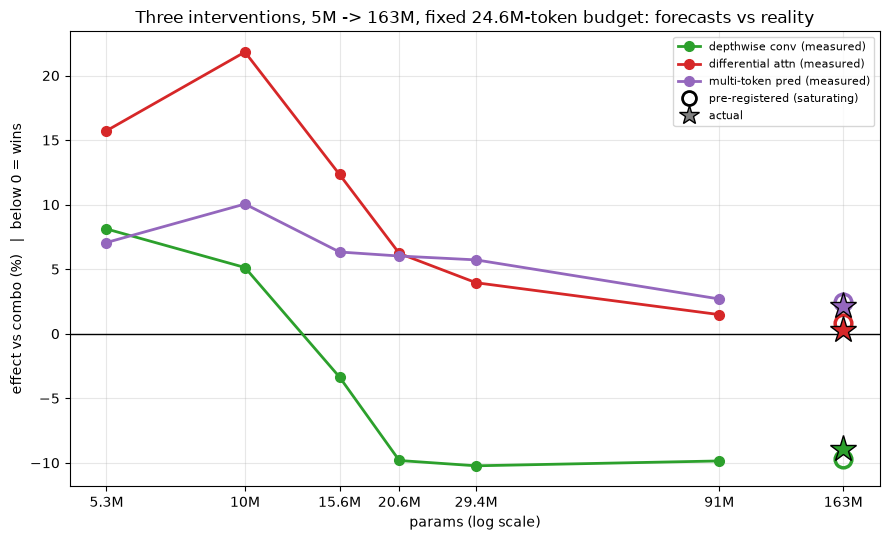

saved ../results/fig_validate160.png


In [13]:
# === Final figure: full 5M -> 163M curves, both rounds of forecasts vs reality ===
import matplotlib.pyplot as plt
colors = {"combo_conv3": "tab:green", "combo_diff": "tab:red", "combo_mtp": "tab:purple"}
labels = {"combo_conv3": "depthwise conv", "combo_diff": "differential attn", "combo_mtp": "multi-token pred"}
plt.figure(figsize=(9, 5.5)); plt.axhline(0, color="k", lw=1)
for variant in ["combo_conv3", "combo_diff", "combo_mtp"]:
    pts = delta_points(variant, ORDER)
    c = colors[variant]
    mm = {sz: np.mean([y for z, x, y in pts if z == sz]) for sz in ORDER if any(z == sz for z, x, y in pts)}
    plt.plot([X[s] for s in mm], list(mm.values()), "o-", color=c, ms=7, lw=2, label=f"{labels[variant]} (measured)")
    ds = [100.0 * (v160[(variant, s)] - v160[("combo", s)]) / v160[("combo", s)]
          for s in ("0", "1") if (variant, s) in v160 and ("combo", s) in v160]
    plt.plot(X160, PRE160[variant]["saturating"], "o", mfc="none", mec=c, ms=12, mew=2.5)
    if ds: plt.plot(X160, np.mean(ds), "*", color=c, ms=20, mec="k")
plt.plot([], [], "o", mfc="none", mec="k", ms=10, mew=2, label="pre-registered (saturating)")
plt.plot([], [], "*", color="gray", ms=15, mec="k", label="actual")
xt = [X[s] for s in ORDER] + [X160]
plt.xticks(xt, ["5.3M", "10M", "15.6M", "20.6M", "29.4M", "91M", "163M"])
plt.xlabel("params (log scale)"); plt.ylabel("effect vs combo (%)   |  below 0 = wins")
plt.title("Three interventions, 5M -> 163M, fixed 24.6M-token budget: forecasts vs reality")
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("../results/fig_validate160.png", dpi=150)
plt.show(); print("saved ../results/fig_validate160.png")


## Reading this

Round-2 scorecard: saturating vs linear, three interventions, one decade of prospective
extrapolation total (29.4M -> 163M from the original ladder). This figure plus the two graded
CSVs (91M, 163M) is the paper's centerpiece.
